# Training a YOLO Model on Imbalanced Data
### A hands-on workshop with YOLO11n on GTSDB

Real detection datasets are imbalanced: a few *head* classes own most of
the annotations while a long *tail* of rare classes has only a handful of
examples. Models trained naively would score well on average because the
average is dominated by the head — while quietly failing on exactly the rare
classes that often matter most. 

We use the **German Traffic Sign Detection Benchmark (GTSDB)** — 43 classes, 600 train / 300 val images — as a small example of the problem, then walk the standard interventions: re-balance the data, re-weight the loss, and augment.

**What you will do**
- Quantify the imbalance before touching a model: class counts, box sizes,
  co-occurrence.
- Establish a **baseline** and read its scores head vs tail 
- Train using each intervention and compare it against the baseline.

| family | arms | idea |
|--------|------|------|
| Re-balancing (data) | `oversample`, `rfs` | show rare classes more often |
| Class-sensitive (loss) | `cls_pw`, `focal` | make rare-class errors cost more |
| Augmentation | `cutmix` | synthesize fresh context for rare classes |

## 0. Install dependencies

In [42]:
%pip install -q \
    "ultralytics==8.4.144" \
    "numpy>=1.24" \
    "opencv-python>=4.8" \
    "Pillow>=10.0" \
    "matplotlib>=3.8" \
    "pandas>=2.0" \
    "pyyaml>=6.0"


Note: you may need to restart the kernel to use updated packages.


## 1. Setup & Paths


In [43]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

In [44]:
PROJECT = Path.cwd().resolve()
RS_DIR = PROJECT / "src"
MODELS = PROJECT / "models"
DATA_ROOT = PROJECT / "datasets"
RUNS = PROJECT / "runs"

_DS = yaml.safe_load((DATA_ROOT / "gtsdb_yolo.yaml").read_text(encoding="utf-8"))
CLASS_NAMES = [v for _, v in sorted(_DS["names"].items(), key=lambda kv: int(kv[0]))]
NC = len(CLASS_NAMES)

HEAD_MIN = 21          # >= this many train instances -> head group
TAIL_MAX = 20          # <= this many train instances -> tail group

import torch
DEVICE = "0" if torch.cuda.is_available() else "cpu"
print(f"Project: {PROJECT}")
print(f"Classes: {NC}   device: {DEVICE}")

Project: C:\Users\marxa\OneDrive\Documents\ACADEMIA\MSLABS2\class-imbalance-workshop-release
Classes: 43   device: 0


In [45]:
if str(RS_DIR) not in sys.path:
    sys.path.insert(0, str(RS_DIR))
    
DATA_YAML = DATA_ROOT / "gtsdb_yolo.yaml"

assert DATA_YAML.exists(), f"missing base dataset yaml: {DATA_YAML}"

In [46]:
from workshop_helpers import (
    create_helpers,
    metrics_table,
    group_summary,
    per_class_map_chart,
    compare_arms_bars,
    training_overview,
    group_delta_table,
    per_class_delta_table,
    per_class_delta_chart,
    metric_matrix,
    group_heatmap,
    per_class_heatmap,
    rank_arms,
)

from prepare_data import build_oversample, build_rfs

_helpers = create_helpers(runs=RUNS, data_root=DATA_ROOT)

has_weights = _helpers["has_weights"]
has_eval = _helpers["has_eval"]
finish_run = _helpers["finish_run"]
load_metrics = _helpers["load_metrics"]


## 2. The Dataset

**GTSDB** (German Traffic Sign Detection Benchmark) is a detection dataset of
road scenes with 43 traffic-sign classes. It exhibits class imbalance in the transportation domain: many prohibition/warning signs appear a few
dozen times, and the rarest class appears once.

The data is already in Ultralytics YOLO format under `datasets/gtsdb_yolo/`:

```
datasets/gtsdb_yolo/
  images/train/  images/val/
  labels/train/  labels/val/   
```


In [47]:
print(DATA_YAML.read_text(encoding="utf-8"))

train: gtsdb_yolo/images/train
val: gtsdb_yolo/images/val
nc: 43
names:
  0: speed_limit_20
  1: speed_limit_30
  2: speed_limit_50
  3: speed_limit_60
  4: speed_limit_70
  5: speed_limit_80
  6: restriction_ends_80
  7: speed_limit_100
  8: speed_limit_120
  9: no_overtaking
  10: no_overtaking_trucks
  11: priority_at_next_intersection
  12: priority_road
  13: give_way
  14: stop
  15: no_traffic_both_ways
  16: no_trucks
  17: no_entry
  18: danger
  19: bend_left
  20: bend_right
  21: bend
  22: uneven_road
  23: slippery_road
  24: road_narrows
  25: construction
  26: traffic_signal
  27: pedestrian_crossing
  28: school_crossing
  29: cycles_crossing
  30: snow
  31: animals
  32: restriction_ends
  33: go_right
  34: go_left
  35: go_straight
  36: go_right_or_straight
  37: go_left_or_straight
  38: keep_right
  39: keep_left
  40: roundabout
  41: restriction_ends_overtaking
  42: restriction_ends_overtaking_trucks



## 3. Exploratory Data Analysis (EDA)

Before training, quantify what makes this dataset hard. Four questions:

1. **What do the images look like?** 
2. **How uneven are the class counts?** 
3. **How are the boxes distributed?** 
4. **Do classes appear together?** 


### 3.1 Train / validation inventory

Count images and labels on each split and check if they match. A mismatch
would mean images with no label file or labels that do not point to any image.


In [48]:
from collections import Counter
from PIL import Image

TRAIN_LABELS = DATA_ROOT / "gtsdb_yolo" / "labels" / "train"
TRAIN_IMAGES = DATA_ROOT / "gtsdb_yolo" / "images" / "train"
VAL_LABELS = DATA_ROOT / "gtsdb_yolo" / "labels" / "val"
VAL_IMAGES = DATA_ROOT / "gtsdb_yolo" / "images" / "val"

train_imgs = sorted(TRAIN_IMAGES.glob("*.jpg"))
val_imgs = sorted(VAL_IMAGES.glob("*.jpg"))
train_lbls = sorted(TRAIN_LABELS.glob("*.txt"))
val_lbls = sorted(VAL_LABELS.glob("*.txt"))

print(f"Train: {len(train_imgs)} images, {len(train_lbls)} labels")
print(f"Val:   {len(val_imgs)} images, {len(val_lbls)} labels")

train_match = {p.stem for p in train_imgs} == {p.stem for p in train_lbls}
val_match = {p.stem for p in val_imgs} == {p.stem for p in val_lbls}
print(f"Train image-label match: {train_match}")
print(f"Val image-label match:   {val_match}")

Train: 600 images, 600 labels
Val:   300 images, 300 labels
Train image-label match: True
Val image-label match:   True


### 3.2 What the images look like

A grid of six sample training images. Every training image is **1360x800**.


In [ ]:
SAMPLE_COUNT = min(6, len(train_imgs))
image_sizes = [Image.open(p).size for p in train_imgs]
widths = [w for w, _ in image_sizes]
heights = [h for _, h in image_sizes]

fig, axes = plt.subplots(2, 3, figsize=(9.5, 5))
for ax, p in zip(axes.flat, train_imgs[:SAMPLE_COUNT]):
    with Image.open(p) as im:
        ax.imshow(im)
    ax.set_title(p.name, fontsize=9)
    ax.axis("off")
for ax in axes.flat[SAMPLE_COUNT:]:
    ax.axis("off")
fig.suptitle("Examples from the GTSDB training set")
plt.tight_layout()
plt.show()

print(f"Width:  min={min(widths)}  max={max(widths)}  median={np.median(widths):.0f}")
print(f"Height: min={min(heights)}  max={max(heights)}  median={np.median(heights):.0f}")
print(f"Unique image sizes: {sorted(set(image_sizes))}")

### 3.3 Class distribution 

The bar chart sorts train classes from most to least frequent. Green bars are
**head** (>= 21 train boxes), red are **tail** (<= 20). There are a few tall green bars on the left, and drops into a long red tail.

Total train instances: 782
Total val instances:   431


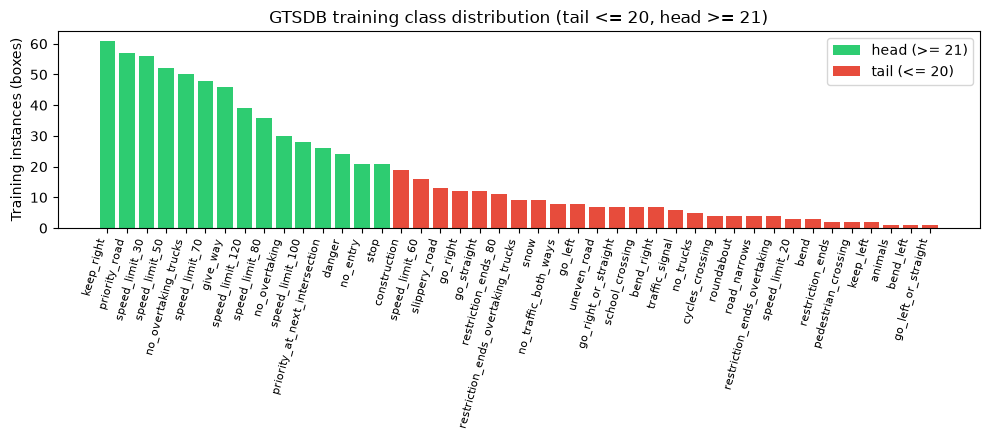

In [ ]:
def parse_yolo_labels(label_dir):
    counts = Counter()
    for lbl in sorted(label_dir.glob("*.txt")):
        for line in lbl.read_text().strip().splitlines():
            if line.strip():
                counts[int(line.split()[0])] += 1
    return counts

raw_counts = parse_yolo_labels(TRAIN_LABELS)
train_counts = np.array([raw_counts.get(c, 0) for c in range(NC)])
val_counts = parse_yolo_labels(VAL_LABELS)
print(f"Total train instances: {train_counts.sum()}")
print(f"Total val instances:   {sum(val_counts.values())}")

order = np.argsort(-train_counts)
colors = ["#2ecc71" if train_counts[c] >= HEAD_MIN else "#e74c3c" for c in order]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(NC), train_counts[order], color=colors)
ax.set_xticks(range(NC))
ax.set_xticklabels([CLASS_NAMES[c] for c in order], rotation=75, ha="right", fontsize=8)
ax.set_ylabel("Training instances (boxes)")
ax.set_title(f"GTSDB training class distribution (tail <= {TAIL_MAX}, head >= {HEAD_MIN})")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor="#2ecc71", label=f"head (>= {HEAD_MIN})"),
                   Patch(facecolor="#e74c3c", label=f"tail (<= {TAIL_MAX})")])
plt.tight_layout()
plt.show()

In [ ]:
pos = train_counts[train_counts > 0]
print(f"Imbalance ratio (most/least frequent class): {pos.max()}/{pos.min()} = {pos.max()/pos.min():.1f}x")

head_classes = [c for c in range(NC) if train_counts[c] >= HEAD_MIN]
tail_classes = [c for c in range(NC) if train_counts[c] <= TAIL_MAX]
head_summary = pd.DataFrame({
    "Group": ["Head", "Tail"],
    "Classes": [len(head_classes), len(tail_classes)],
    "Instances": [int(train_counts[head_classes].sum()), int(train_counts[tail_classes].sum())],
})
display(head_summary)

Imbalance ratio (most/least frequent class): 61/1 = 61.0x


,Group,Classes,Instances
0,Head,15,595
1,Tail,28,187


### 3.4 Box-level imbalance

In object detection, we also care about bounding boxes. Let us find out the number of boxes in each training image along with the box area sizes.

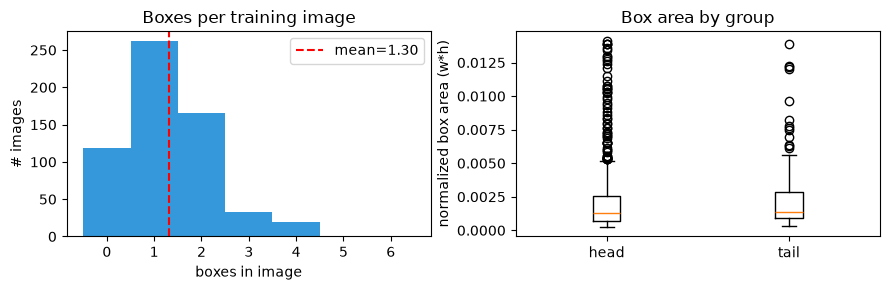

Mean boxes/image: 1.30
Median box area  head=0.00126  tail=0.00139


In [ ]:
from collections import defaultdict

boxes_per_image = []
areas_by_group = {"head": [], "tail": []}
for lbl in sorted(TRAIN_LABELS.glob("*.txt")):
    lines = [l for l in lbl.read_text().strip().splitlines() if l.strip()]
    boxes_per_image.append(len(lines))
    for l in lines:
        c, cx, cy, w, h = map(float, l.split())
        c = int(c)
        areas_by_group["head" if train_counts[c] >= HEAD_MIN else "tail"].append(w * h)

fig, axes = plt.subplots(1, 2, figsize=(9, 3))

axes[0].hist(boxes_per_image, bins=range(0, max(boxes_per_image) + 2), align="left", color="#3498db")
axes[0].set_title("Boxes per training image")
axes[0].set_xlabel("boxes in image"); axes[0].set_ylabel("# images")
axes[0].axvline(np.mean(boxes_per_image), color="red", ls="--",
                label=f"mean={np.mean(boxes_per_image):.2f}")
axes[0].legend()

axes[1].boxplot([areas_by_group["head"], areas_by_group["tail"]])
axes[1].set_xticks([1, 2]); axes[1].set_xticklabels(["head", "tail"])
axes[1].set_ylabel("normalized box area (w*h)")
axes[1].set_title("Box area by group")
plt.tight_layout()
plt.show()

print(f"Mean boxes/image: {np.mean(boxes_per_image):.2f}")
print(f"Median box area  head={np.median(areas_by_group['head']):.5f}  tail={np.median(areas_by_group['tail']):.5f}")

### 3.5 Co-occurrence

The heatmap counts how often each pair of classes appears in the same training image.


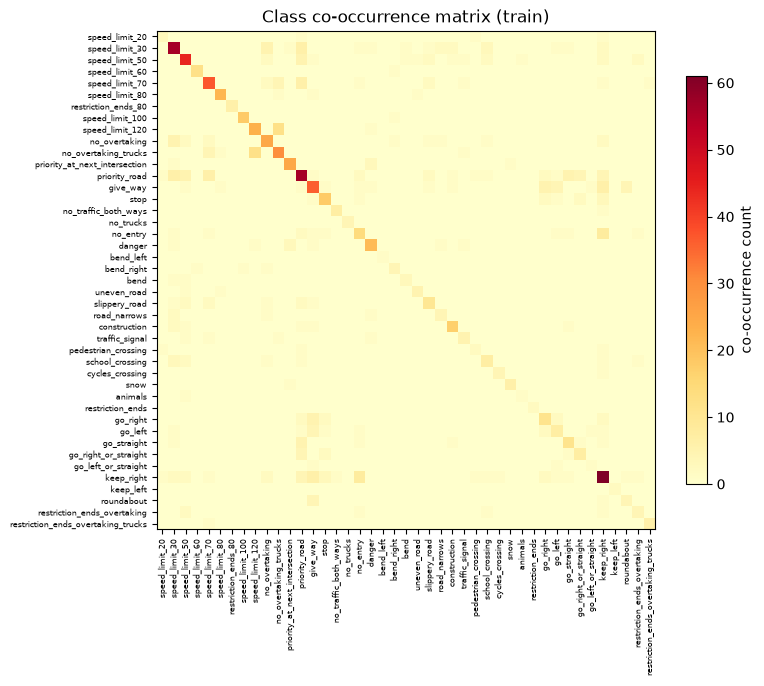

In [ ]:
cooccur = np.zeros((NC, NC), dtype=int)
for lbl in sorted(TRAIN_LABELS.glob("*.txt")):
    present = set()
    for line in lbl.read_text().strip().splitlines():
        if line.strip():
            present.add(int(line.split()[0]))
    for c1 in present:
        for c2 in present:
            cooccur[c1][c2] += 1

fig, ax = plt.subplots(figsize=(8, 6.8))
im = ax.imshow(cooccur, cmap="YlOrRd")
ax.set_xticks(range(NC)); ax.set_yticks(range(NC))
ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=6)
ax.set_yticklabels(CLASS_NAMES, fontsize=6)
ax.set_title("Class co-occurrence matrix (train)")
plt.colorbar(im, ax=ax, shrink=0.8, label="co-occurrence count")
plt.tight_layout()
plt.show()

## 4. Baseline Model (YOLO11n)

The baseline uses the original data and standard configuration. Models trained with interventions will be compared against it.


In [ ]:
if has_weights("baseline"):
    print("[LOAD] baseline - best.pt present; training skipped")
else:
    print("[TRAIN] baseline - no checkpoint; running model.train(...)")
    from ultralytics import YOLO
    model = YOLO(str(MODELS / "yolo11n.pt"))
    model.train(
        data=str(DATA_ROOT / "gtsdb_yolo.yaml"),
        epochs=100,
        imgsz=1280,
        batch=16,
        device=DEVICE,
        seed=0,
        deterministic=True,
        plots=True,
        project=str(RUNS),
        name="baseline",
        exist_ok=True,
    )
    finish_run("baseline", model.trainer.save_dir)

[LOAD] baseline - best.pt present; training skipped


Below is the baseline's overall / head / tail scores.


In [ ]:
display(group_summary("baseline", RUNS).round(3))

,mAP50,mAP50-95,Precision,Recall
overall,0.526,0.455,0.671,0.472
head,0.807,0.693,0.717,0.782
tail,0.376,0.328,0.646,0.306


Below is the per-class mAP50, grouped head vs tail. 

Most green (head) bars sit high, while red (tail) bars cluster near zero. A tail class with one training example cannot realistically be validated, so zeros there are expected.


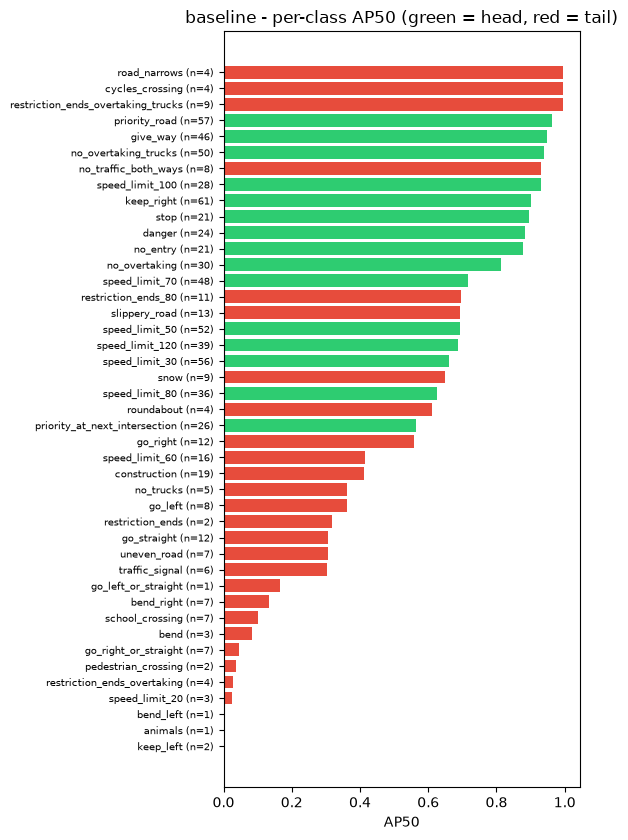

In [ ]:
per_class_map_chart("baseline", RUNS, CLASS_NAMES, metric="AP50")

### Baseline: training curves

Below are the plots of the **overall loss** (box + cls + dfl) and **validation mAP50**.


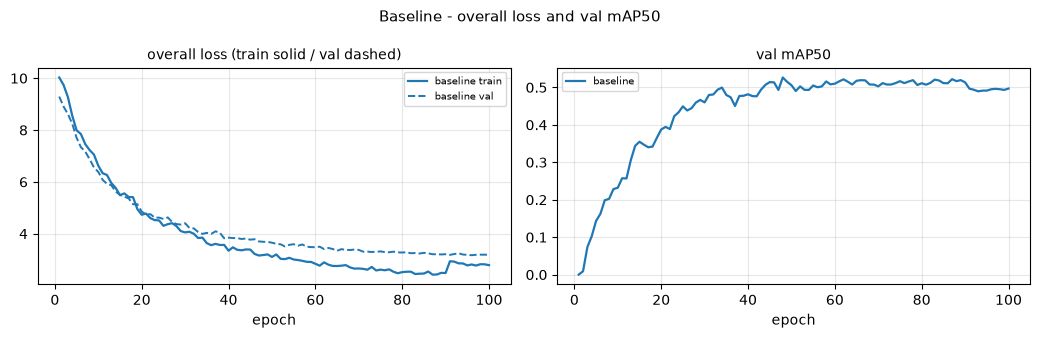

In [ ]:
if (RUNS / "baseline" / "metrics.json").exists():
    training_overview(["baseline"], RUNS, "Baseline - overall loss and val mAP50")
else:
    print("[baseline: not evaluated yet - run gtsdb_eval first]")


## 5. Family 1: Class Re-balancing

Two **data-level** interventions that change how often each class is *seen*:

- **Oversample** — duplicate whole images containing rare classes until every
  class reaches the largest count.
- **Repeat-Factor Sampling (RFS)** — resample *by image frequency*:
  `r_i = max(1, sqrt(t / f_c))`. Gentler than naive oversampling.



[ovs] gtsdb_yolo-oversample.yaml already present -> nothing to build
[ovs] label files 600 -> 1926
[ovs] instances 782 -> 3309 (+2527)
[ovs] rarest class 1 -> 61 instances; imbalance 61:1 -> 253:61
[ovs] classes raised to >= baseline max: 43/43


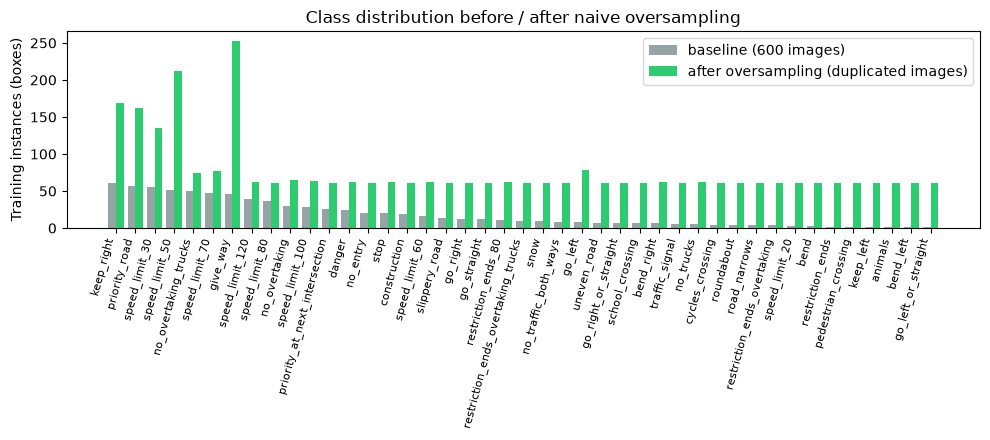

In [ ]:
# Build the oversample variant 
OVERSAMPLE_YAML = DATA_ROOT / "gtsdb_yolo-oversample.yaml"

if not OVERSAMPLE_YAML.exists():
    build_oversample(DATA_ROOT, "gtsdb_yolo", CLASS_NAMES)
else:
    print(f"[ovs] {OVERSAMPLE_YAML.name} already present -> nothing to build")

# visualization of class distribution 
OVS_LABELS = DATA_ROOT / "gtsdb_yolo-oversample" / "labels" / "train"
if OVS_LABELS.exists():
    ovs_raw = parse_yolo_labels(OVS_LABELS)
    ovs_counts = np.array([ovs_raw.get(c, 0) for c in range(NC)])

    base_pos = train_counts[train_counts > 0]
    ovs_pos = ovs_counts[ovs_counts > 0]
    print(f"[ovs] label files {len(train_imgs)} -> {len(list(OVS_LABELS.glob('*.txt')))}")
    print(f"[ovs] instances {int(train_counts.sum())} -> {int(ovs_counts.sum())}"
          f" (+{int(ovs_counts.sum() - train_counts.sum())})")
    print(f"[ovs] rarest class {int(base_pos.min())} -> {int(ovs_pos.min())} instances;"
          f" imbalance {int(train_counts.max())}:{int(base_pos.min())} ->"
          f" {int(ovs_counts.max())}:{int(ovs_pos.min())}")
    print(f"[ovs] classes raised to >= baseline max: {int((ovs_counts >= train_counts.max()).sum())}/{NC}")

    base_order = np.argsort(-train_counts)     
    x = np.arange(NC)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(x - 0.2, train_counts[base_order], width=0.4,
           label="baseline (600 images)", color="#95a5a6")
    ax.bar(x + 0.2, ovs_counts[base_order], width=0.4,
           label="after oversampling (duplicated images)", color="#2ecc71")
    ax.set_xticks(x)
    ax.set_xticklabels([CLASS_NAMES[c] for c in base_order], rotation=75, ha="right", fontsize=8)
    ax.set_ylabel("Training instances (boxes)")
    ax.set_title("Class distribution before / after naive oversampling")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("[ovs] variant labels not on disk -> run the build cell above first")

In [ ]:
if has_weights("oversample"):
    print("[LOAD] oversample - best.pt present; training skipped")
else:
    print("[TRAIN] oversample - no checkpoint; running model.train(...)")
    from ultralytics import YOLO
    model = YOLO(str(MODELS / "yolo11n.pt"))
    model.train(
        data=str(DATA_ROOT / "gtsdb_yolo-oversample.yaml"),
        epochs=100,
        imgsz=1280,
        batch=16,
        device=DEVICE,
        seed=0,
        deterministic=True,
        plots=True,
        project=str(RUNS),
        name="oversample",
        exist_ok=True,
    )
    finish_run("oversample", model.trainer.save_dir)

[LOAD] oversample - best.pt present; training skipped


In [ ]:
display(group_summary("oversample", RUNS).round(3))


,mAP50,mAP50-95,Precision,Recall
overall,0.526,0.449,0.657,0.448
head,0.817,0.698,0.747,0.815
tail,0.370,0.316,0.608,0.252


### Oversample vs baseline


metric     mAP50               mAP50-95               Precision                \
        baseline    arm  delta baseline    arm  delta  baseline    arm  delta   
overall    0.526  0.526 -0.000    0.455  0.449 -0.006     0.671  0.657 -0.014   
head       0.807  0.817  0.010    0.693  0.698  0.004     0.717  0.747  0.030   
tail       0.376  0.370 -0.006    0.328  0.316 -0.012     0.646  0.608 -0.038   

metric    Recall                
        baseline    arm  delta  
overall    0.472  0.448 -0.024  
head       0.782  0.815  0.033  
tail       0.306  0.252 -0.054

,group,n_train,baseline,arm,delta
animals,tail,1,0.0,0.995,0.995
bend,tail,3,0.0825,0.553824,0.471324
roundabout,tail,4,0.610286,0.947857,0.337571
restriction_ends_80,tail,11,0.697,0.995,0.298
speed_limit_80,head,36,0.62484,0.830378,0.205538
school_crossing,tail,7,0.102194,0.28971,0.187516
speed_limit_60,tail,16,0.414489,0.530649,0.11616
no_entry,head,21,0.878857,0.995,0.116143
priority_at_next_intersection,head,26,0.565402,0.661154,0.095752
speed_limit_120,head,39,0.688542,0.755891,0.06735


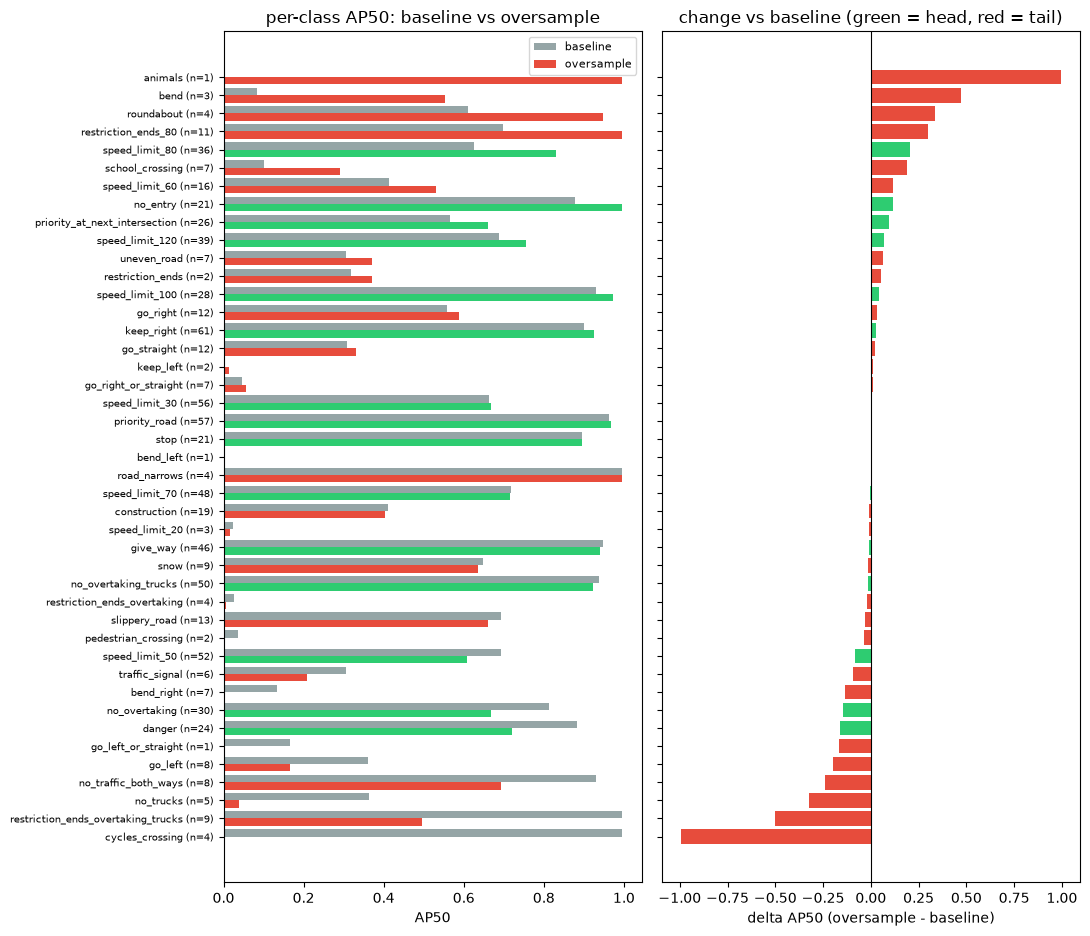

In [ ]:
if (RUNS / "oversample" / "metrics.json").exists():
    display(group_delta_table("oversample", RUNS).round(3))
    display(per_class_delta_table("oversample", RUNS, CLASS_NAMES).round(3))
    per_class_delta_chart("oversample", RUNS, CLASS_NAMES)
else:
    print("[oversample: not evaluated yet - run gtsdb_eval first]")


#### Observations

Group deltas vs the baseline — mAP50 | Precision | Recall:

| group | mAP50 | Precision | Recall |
|---|---|---|---|
| overall | 0.526 (-0.000) | 0.657 (-0.014) | 0.448 (-0.024) |
| head | 0.817 (+0.010) | 0.747 (+0.030) | 0.815 (+0.033) |
| **tail** | 0.370 (-0.006) | 0.608 (-0.038) | 0.252 (-0.054) |

- **Tail classes:** 12 up / 16 down (of 28 present).
- **Top gains:** animals +0.995, bend +0.471, roundabout +0.338.
- **Top drops:** cycles_crossing -0.995, restriction_ends_overtaking_trucks -0.500, no_trucks -0.325.


[rfs] gtsdb_yolo-rfs.yaml already present -> nothing to build
[rfs] list entries 617 from 600 unique images -> 1.03x exposures per image per epoch
[rfs] instances per epoch 782 -> 812 (+30)
[rfs] rarest class 1 -> 3 instances per epoch; largest 61 -> 62


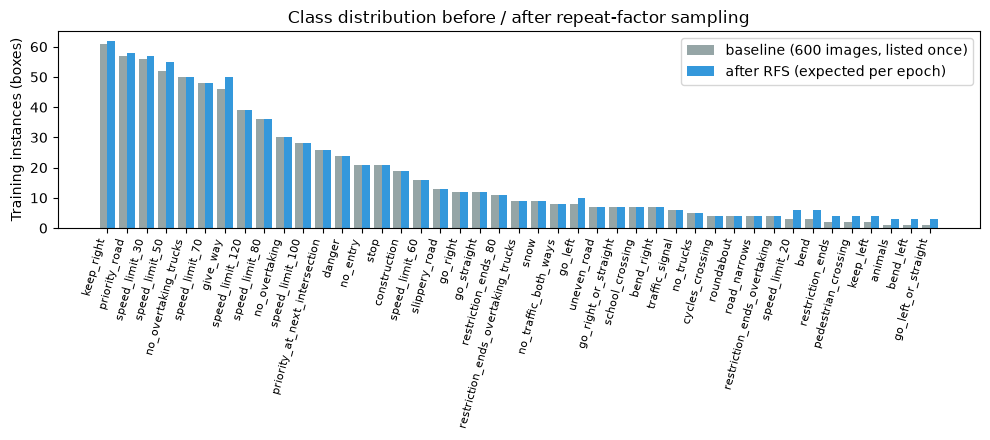

In [ ]:
# Build the RFS variant 
RFS_YAML = DATA_ROOT / "gtsdb_yolo-rfs.yaml"

if not RFS_YAML.exists():
    build_rfs(DATA_ROOT, "gtsdb_yolo", CLASS_NAMES, threshold=0.015)
else:
    print(f"[rfs] {RFS_YAML.name} already present -> nothing to build")

# visualization of class distribution 
RFS_LIST = DATA_ROOT / "gtsdb_yolo-rfs-train.txt"
if RFS_LIST.exists():
    rfs_paths = [ln for ln in RFS_LIST.read_text(encoding="utf-8").splitlines() if ln.strip()]
    rfs_raw = Counter()
    for path_str in rfs_paths:
        label = TRAIN_LABELS / f"{Path(path_str).stem}.txt"
        if label.exists():
            for line in label.read_text().splitlines():
                if line.strip():
                    rfs_raw[int(line.split()[0])] += 1
    rfs_counts = np.array([rfs_raw.get(c, 0) for c in range(NC)])

    unique_images = len(set(rfs_paths))
    print(f"[rfs] list entries {len(rfs_paths)} from {unique_images} unique images"
          f" -> {len(rfs_paths) / max(unique_images, 1):.2f}x exposures per image per epoch")
    print(f"[rfs] instances per epoch {int(train_counts.sum())} -> {int(rfs_counts.sum())}"
          f" (+{int(rfs_counts.sum() - train_counts.sum())})")
    base_pos = train_counts[train_counts > 0]
    rfs_pos = rfs_counts[rfs_counts > 0]
    print(f"[rfs] rarest class {int(base_pos.min())} -> {int(rfs_pos.min())} instances per epoch;"
          f" largest {int(train_counts.max())} -> {int(rfs_counts.max())}")

    base_order = np.argsort(-train_counts)      
    x = np.arange(NC)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(x - 0.2, train_counts[base_order], width=0.4,
           label="baseline (600 images, listed once)", color="#95a5a6")
    ax.bar(x + 0.2, rfs_counts[base_order], width=0.4,
           label="after RFS (expected per epoch)", color="#3498db")
    ax.set_xticks(x)
    ax.set_xticklabels([CLASS_NAMES[c] for c in base_order], rotation=75, ha="right", fontsize=8)
    ax.set_ylabel("Training instances (boxes)")
    ax.set_title("Class distribution before / after repeat-factor sampling")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("[rfs] path list not on disk -> run the build cell above first")

In [ ]:
if has_weights("rfs"):
    print("[LOAD] rfs - best.pt present; training skipped")
else:
    print("[TRAIN] rfs - no checkpoint; running model.train(...)")
    from ultralytics import YOLO
    model = YOLO(str(MODELS / "yolo11n.pt"))
    model.train(
        data=str(DATA_ROOT / "gtsdb_yolo-rfs.yaml"),
        epochs=100,
        imgsz=1280,
        batch=16,
        device=DEVICE,
        seed=0,
        deterministic=True,
        plots=True,
        project=str(RUNS),
        name="rfs",
        exist_ok=True,
    )
    finish_run("rfs", model.trainer.save_dir)

[LOAD] rfs - best.pt present; training skipped


In [ ]:
display(group_summary("rfs", RUNS).round(3))


,mAP50,mAP50-95,Precision,Recall
overall,0.563,0.482,0.681,0.495
head,0.830,0.712,0.799,0.789
tail,0.420,0.358,0.618,0.337


### RFS vs Baseline



metric     mAP50               mAP50-95               Precision                \
        baseline    arm  delta baseline    arm  delta  baseline    arm  delta   
overall    0.526  0.563  0.037    0.455  0.482  0.026     0.671  0.681  0.010   
head       0.807  0.830  0.024    0.693  0.712  0.018     0.717  0.799  0.082   
tail       0.376  0.420  0.044    0.328  0.358  0.030     0.646  0.618 -0.028   

metric    Recall                
        baseline    arm  delta  
overall    0.472  0.495  0.022  
head       0.782  0.789  0.007  
tail       0.306  0.337  0.031

,group,n_train,baseline,arm,delta
bend,tail,3,0.0825,0.995,0.9125
bend_right,tail,7,0.133214,0.535,0.401786
snow,tail,9,0.648131,0.909091,0.26096
speed_limit_80,head,36,0.62484,0.873407,0.248567
go_right_or_straight,tail,7,0.045048,0.276071,0.231023
restriction_ends_80,tail,11,0.697,0.897857,0.200857
construction,tail,19,0.411727,0.59799,0.186262
speed_limit_60,tail,16,0.414489,0.55247,0.137981
no_trucks,tail,5,0.3632,0.476429,0.113229
speed_limit_120,head,39,0.688542,0.767415,0.078873


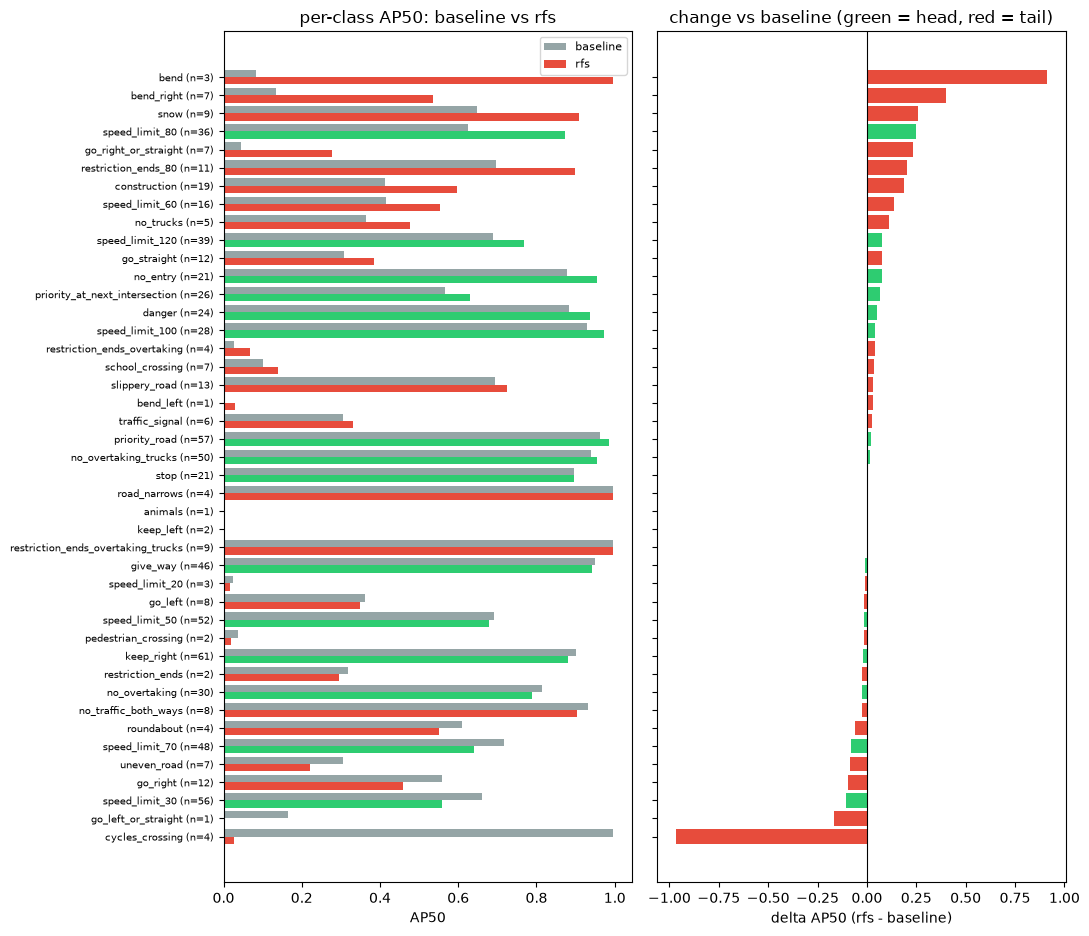

In [ ]:
if (RUNS / "rfs" / "metrics.json").exists():
    display(group_delta_table("rfs", RUNS).round(3))
    display(per_class_delta_table("rfs", RUNS, CLASS_NAMES).round(3))
    per_class_delta_chart("rfs", RUNS, CLASS_NAMES)
else:
    print("[rfs: not evaluated yet - run gtsdb_eval first]")


#### Observations

Group deltas vs the baseline — mAP50 | Precision | Recall:

| group | mAP50 | Precision | Recall |
|---|---|---|---|
| overall | 0.563 (+0.037) | 0.681 (+0.010) | 0.495 (+0.022) |
| head | 0.830 (+0.024) | 0.799 (+0.082) | 0.789 (+0.007) |
| **tail** | 0.420 (+0.044) | 0.618 (-0.028) | 0.337 (+0.031) |

- **Tail classes:** 14 up / 14 down (of 28 present).
- **Top gains:** bend +0.912, bend_right +0.402, snow +0.261.
- **Top drops:** cycles_crossing -0.969, go_left_or_straight -0.166, speed_limit_30 -0.104.

### Family 1 summary


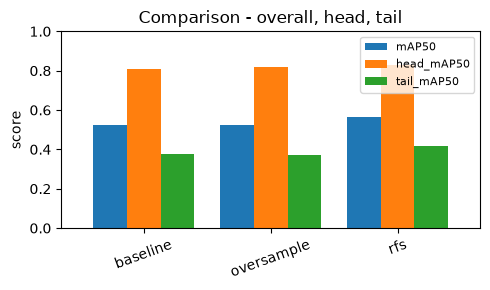

,mAP50,mAP50-95,Precision,Recall,head_mAP50,head_Precision,head_Recall,tail_mAP50,tail_Precision,tail_Recall
baseline,0.526,0.455,0.671,0.472,0.807,0.717,0.782,0.376,0.646,0.306
oversample,0.526,0.449,0.657,0.448,0.817,0.747,0.815,0.370,0.608,0.252
rfs,0.563,0.482,0.681,0.495,0.830,0.799,0.789,0.420,0.618,0.337


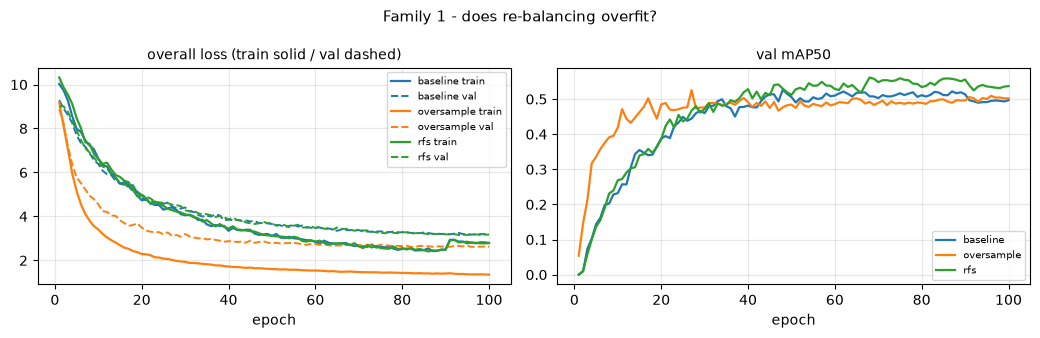

In [ ]:
compare_arms_bars(["baseline", "oversample", "rfs"], RUNS)
display(metrics_table(["baseline", "oversample", "rfs"], RUNS).round(3))
training_overview(["baseline", "oversample", "rfs"], RUNS,
                  "Family 1 - does re-balancing overfit?")


## 6. Family 2: Class-Sensitive Learning

Instead of changing how often classes appear, change what the loss penalises.
Two loss-level levers:

- **Class-weighted BCE** (native `cls_pw`) — scales the classification loss per
  class by inverse frequency so rare classes weigh more. 
- **Focal loss** — down-weights easy negatives so the classification
  term focuses on hard/rare examples. `alpha` is the positive/rare-class weight and `gamma` is
  the focusing strength.


### Class weighting (`cls_pw`)



In [ ]:
from ultralytics import YOLO

CW_ARM = "cls_pw"
CW_PW = 1.0
if has_weights(CW_ARM):
    print(f"[LOAD] {CW_ARM} - best.pt present; training skipped")
else:
    print(f"[TRAIN] {CW_ARM} - native class weights (cls_pw={CW_PW})")
    model = YOLO(str(MODELS / "yolo11n.pt"))
    model.train(
        data=str(DATA_ROOT / "gtsdb_yolo.yaml"),
        epochs=100,
        imgsz=1280,
        batch=16,
        device=DEVICE,
        seed=0,
        deterministic=True,
        plots=True,
        cls_pw=CW_PW,
        project=str(RUNS),
        name=CW_ARM,
        exist_ok=True,
    )
    finish_run(CW_ARM, model.trainer.save_dir)

display(group_summary(CW_ARM, RUNS).round(3))


[LOAD] cls_pw - best.pt present; training skipped


,mAP50,mAP50-95,Precision,Recall
overall,0.453,0.392,0.517,0.440
head,0.691,0.608,0.607,0.721
tail,0.325,0.277,0.468,0.290


metric     mAP50               mAP50-95               Precision                \
        baseline    arm  delta baseline    arm  delta  baseline    arm  delta   
overall    0.526  0.453 -0.074    0.455  0.392 -0.063     0.671  0.517 -0.154   
head       0.807  0.691 -0.116    0.693  0.608 -0.085     0.717  0.607 -0.110   
tail       0.376  0.325 -0.051    0.328  0.277 -0.051     0.646  0.468 -0.177   

metric    Recall                
        baseline    arm  delta  
overall    0.472  0.440 -0.032  
head       0.782  0.721 -0.061  
tail       0.306  0.290 -0.016

,group,n_train,baseline,arm,delta
bend,tail,3,0.0825,0.995,0.9125
restriction_ends_80,tail,11,0.697,0.95475,0.25775
go_right_or_straight,tail,7,0.045048,0.180909,0.135861
roundabout,tail,4,0.610286,0.709944,0.099659
speed_limit_20,tail,3,0.024268,0.0995,0.075232
pedestrian_crossing,tail,2,0.036852,0.110556,0.073704
no_entry,head,21,0.878857,0.931023,0.052166
no_traffic_both_ways,tail,8,0.930385,0.9775,0.047115
speed_limit_100,head,28,0.930256,0.972895,0.042638
priority_road,head,57,0.962881,0.981994,0.019113


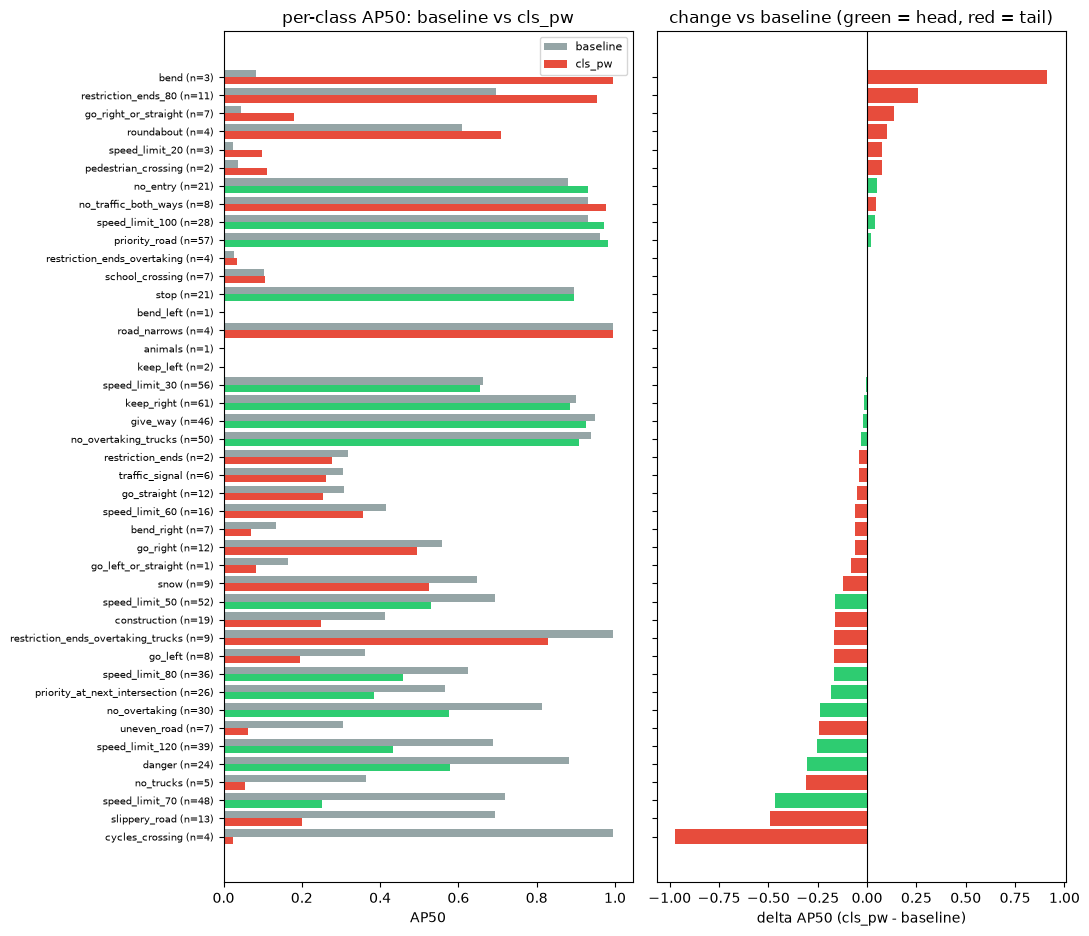

In [ ]:
if (RUNS / CW_ARM / "metrics.json").exists():
    display(group_delta_table(CW_ARM, RUNS).round(3))
    display(per_class_delta_table(CW_ARM, RUNS, CLASS_NAMES).round(3))
    per_class_delta_chart(CW_ARM, RUNS, CLASS_NAMES)
else:
    print(f"[{CW_ARM}: not evaluated yet - run gtsdb_eval first]")

#### Observations

Group deltas vs the baseline — mAP50 | Precision | Recall:

| group | mAP50 | Precision | Recall |
|---|---|---|---|
| overall | 0.453 (-0.074) | 0.517 (-0.154) | 0.440 (-0.032) |
| head | 0.691 (-0.116) | 0.607 (-0.110) | 0.721 (-0.061) |
| **tail** | 0.325 (-0.051) | 0.468 (-0.177) | 0.290 (-0.016) |

- **Tail classes:** 9 up / 19 down (of 28 present).
- **Top gains:** bend +0.912, restriction_ends_80 +0.258, go_right_or_straight +0.136.
- **Top drops:** cycles_crossing -0.971, slippery_road -0.492, speed_limit_70 -0.466.


### cls_pw: training curves

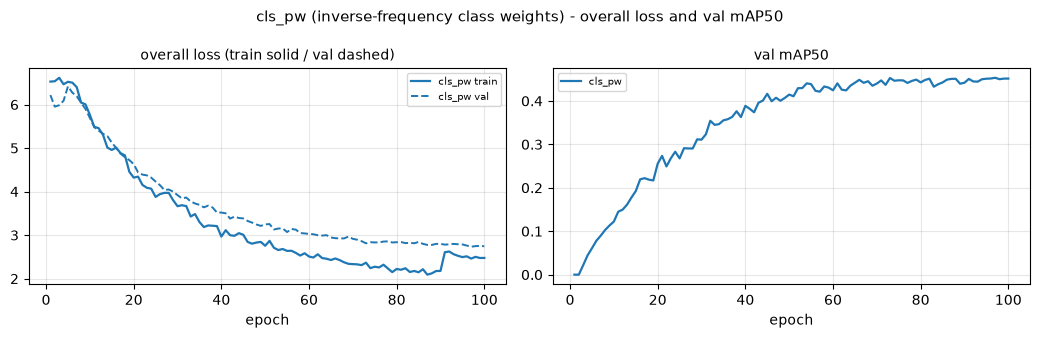

In [ ]:
if (RUNS / CW_ARM / "results.csv").exists():
    training_overview([CW_ARM], RUNS,
                      f"{CW_ARM} (inverse-frequency class weights) - overall loss and val mAP50")
else:
    print(f"[{CW_ARM}: no results.csv yet - train this arm first]")


In [ ]:
from imbalance_losses import make_focal_trainer

FOCAL_ARMS = {
    "focal": dict(alpha=0.25, gamma=2.0),
}

FOCAL_CLS = 5.0

for arm, kw in FOCAL_ARMS.items():
    if has_weights(arm):
        print(f"[LOAD] {arm} - best.pt present; training skipped")
        continue
    print(f"[TRAIN] {arm} - focal "
          f"(gamma={kw['gamma']}, alpha={kw['alpha']}, cls={FOCAL_CLS})")
    Trainer = make_focal_trainer(gamma=kw["gamma"], alpha=kw["alpha"])
    trainer = Trainer(overrides=dict(
        model=str(MODELS / "yolo11n.pt"),
        data=str(DATA_ROOT / "gtsdb_yolo.yaml"),
        epochs=100, imgsz=1280, batch=16, device=DEVICE,
        seed=0, deterministic=True, plots=True, cls=FOCAL_CLS,
        project=str(RUNS), name=arm, exist_ok=True,
    ))
    trainer.train()
    finish_run(arm, trainer.save_dir)


[LOAD] focal - best.pt present; training skipped


In [ ]:
for arm in FOCAL_ARMS:
    display(group_summary(arm, RUNS).round(3))


,mAP50,mAP50-95,Precision,Recall
overall,0.530,0.459,0.651,0.457
head,0.831,0.714,0.763,0.782
tail,0.368,0.322,0.590,0.283


### Focal vs Baseline

Per-class deltas and computed observations for focal loss
(`focal`, gamma=2, alpha=0.25), relative to the baseline.


metric     mAP50               mAP50-95               Precision                \
        baseline    arm  delta baseline    arm  delta  baseline    arm  delta   
overall    0.526  0.530  0.004    0.455  0.459  0.004     0.671  0.651 -0.020   
head       0.807  0.831  0.025    0.693  0.714  0.021     0.717  0.763  0.046   
tail       0.376  0.368 -0.008    0.328  0.322 -0.006     0.646  0.590 -0.056   

metric    Recall                
        baseline    arm  delta  
overall    0.472  0.457 -0.015  
head       0.782  0.782  0.000  
tail       0.306  0.283 -0.023

,group,n_train,baseline,arm,delta
pedestrian_crossing,tail,2,0.036852,0.995,0.958148
go_straight,tail,12,0.307301,0.589103,0.281802
restriction_ends_80,tail,11,0.697,0.861616,0.164616
speed_limit_30,head,56,0.661913,0.795333,0.13342
restriction_ends,tail,2,0.318571,0.451332,0.132761
go_right,tail,12,0.5575,0.68452,0.12702
speed_limit_50,head,52,0.69238,0.789232,0.096852
school_crossing,tail,7,0.102194,0.194778,0.092585
speed_limit_60,tail,16,0.414489,0.504455,0.089966
go_left_or_straight,tail,1,0.165833,0.24875,0.082917


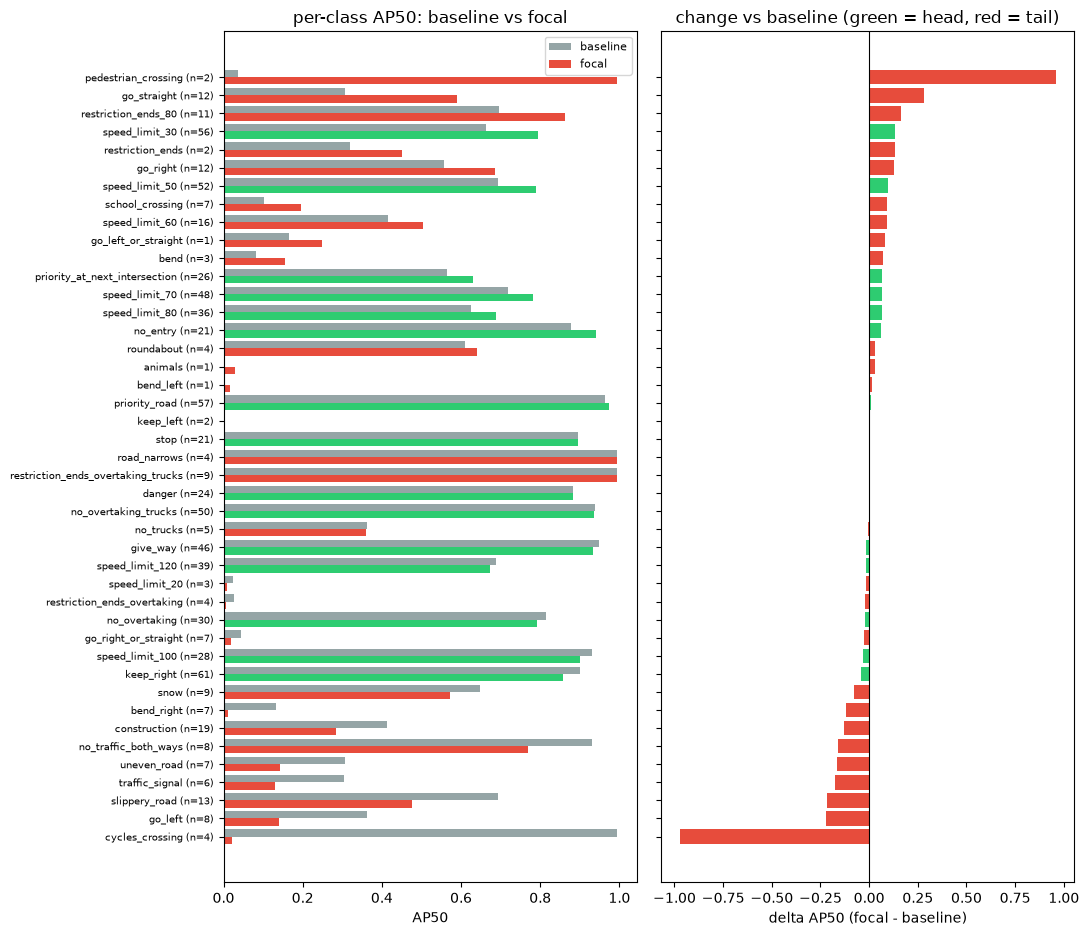

In [ ]:
if (RUNS / "focal" / "metrics.json").exists():
    display(group_delta_table("focal", RUNS).round(3))
    display(per_class_delta_table("focal", RUNS, CLASS_NAMES).round(3))
    per_class_delta_chart("focal", RUNS, CLASS_NAMES)
else:
    print("[focal: not evaluated yet - run gtsdb_eval first]")


#### Observations

Group deltas vs the baseline — mAP50 | Precision | Recall:

| group | mAP50 | Precision | Recall |
|---|---|---|---|
| overall | 0.530 (+0.004) | 0.651 (-0.020) | 0.457 (-0.015) |
| head | 0.831 (+0.025) | 0.763 (+0.046) | 0.782 (+0.000) |
| **tail** | 0.368 (-0.008) | 0.590 (-0.056) | 0.283 (-0.023) |

- **Tail classes:** 13 up / 15 down (of 28 present).
- **Top gains:** pedestrian_crossing +0.958, go_straight +0.282, restriction_ends_80 +0.165.
- **Top drops:** cycles_crossing -0.973, go_left -0.221, slippery_road -0.216.


### Focal: training curves

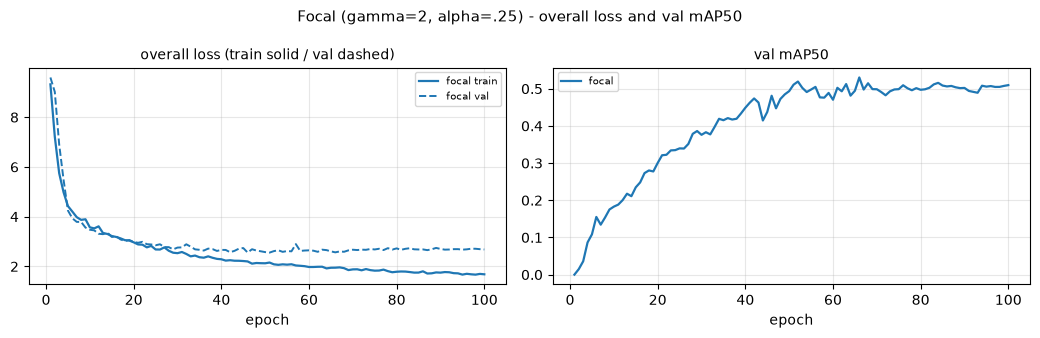

In [ ]:
if (RUNS / "focal" / "results.csv").exists():
    training_overview(["focal"], RUNS, "Focal (gamma=2, alpha=.25) - overall loss and val mAP50")
else:
    print("[focal: no results.csv yet - train this arm first]")


### Family 2 summary

Both loss-level arms against the baseline. **Re-weighting the
loss does not move the tail:** `focal` moves only the head (head **+0.025**,
tail **−0.008**) and `cls_pw` loses *both* groups (head **−0.116**, tail
**−0.051**).


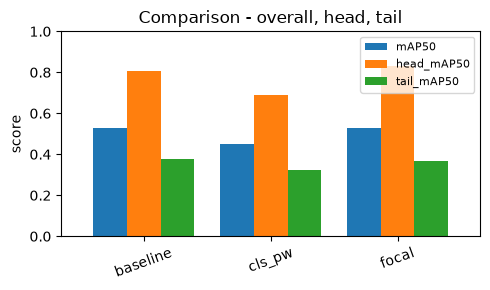

,mAP50,mAP50-95,Precision,Recall,head_mAP50,head_Precision,head_Recall,tail_mAP50,tail_Precision,tail_Recall
baseline,0.526,0.455,0.671,0.472,0.807,0.717,0.782,0.376,0.646,0.306
cls_pw,0.453,0.392,0.517,0.440,0.691,0.607,0.721,0.325,0.468,0.290
focal,0.530,0.459,0.651,0.457,0.831,0.763,0.782,0.368,0.590,0.283


In [ ]:
G2_ARMS = [a for a in ["baseline", "cls_pw", "focal"]
           if (RUNS / a / "metrics.json").exists()]
compare_arms_bars(G2_ARMS, RUNS)
display(metrics_table(G2_ARMS, RUNS).round(3))

## 7. Family 3: Data Augmentation

Native Ultralytics augmentation. **CutMix** pastes a rectangle from one image
onto another and carries the correct labels along — rare classes get new,
partially-occluded contexts instead of being memorised as crops. 

![CutMix sample: a rectangle is cut from image B and pasted onto image A, carrying a rare tail sign with it](assets/cutmix_example.jpg)


In [ ]:
if has_weights("cutmix"):
    print("[LOAD] cutmix - best.pt present; training skipped")
else:
    print("[TRAIN] cutmix - no checkpoint; running model.train(...) with cutmix=0.15")
    from ultralytics import YOLO
    model = YOLO(str(MODELS / "yolo11n.pt"))
    model.train(
        data=str(DATA_ROOT / "gtsdb_yolo.yaml"),
        epochs=100,
        imgsz=1280,
        batch=16,
        device=DEVICE,
        seed=0,
        deterministic=True,
        plots=True,
        cutmix=0.15,
        project=str(RUNS),
        name="cutmix",
        exist_ok=True,
    )
    finish_run("cutmix", model.trainer.save_dir)

[LOAD] cutmix - best.pt present; training skipped


In [ ]:
display(group_summary("cutmix", RUNS).round(3))


,mAP50,mAP50-95,Precision,Recall
overall,0.549,0.478,0.577,0.530
head,0.824,0.717,0.706,0.852
tail,0.401,0.350,0.508,0.358


### Cutmix vs baseline



metric     mAP50               mAP50-95               Precision                \
        baseline    arm  delta baseline    arm  delta  baseline    arm  delta   
overall    0.526  0.549  0.023    0.455  0.478  0.023     0.671  0.577 -0.093   
head       0.807  0.824  0.018    0.693  0.717  0.024     0.717  0.706 -0.011   
tail       0.376  0.401  0.025    0.328  0.350  0.022     0.646  0.508 -0.137   

metric    Recall                
        baseline    arm  delta  
overall    0.472  0.530  0.058  
head       0.782  0.852  0.070  
tail       0.306  0.358  0.052

,group,n_train,baseline,arm,delta
pedestrian_crossing,tail,2,0.036852,0.995,0.958148
bend,tail,3,0.0825,0.828333,0.745833
speed_limit_80,head,36,0.62484,0.810139,0.185299
snow,tail,9,0.648131,0.829,0.180869
restriction_ends_80,tail,11,0.697,0.875,0.178
school_crossing,tail,7,0.102194,0.224228,0.122034
go_right_or_straight,tail,7,0.045048,0.165,0.119952
speed_limit_20,tail,3,0.024268,0.142143,0.117875
speed_limit_60,tail,16,0.414489,0.524183,0.109694
roundabout,tail,4,0.610286,0.698994,0.088708


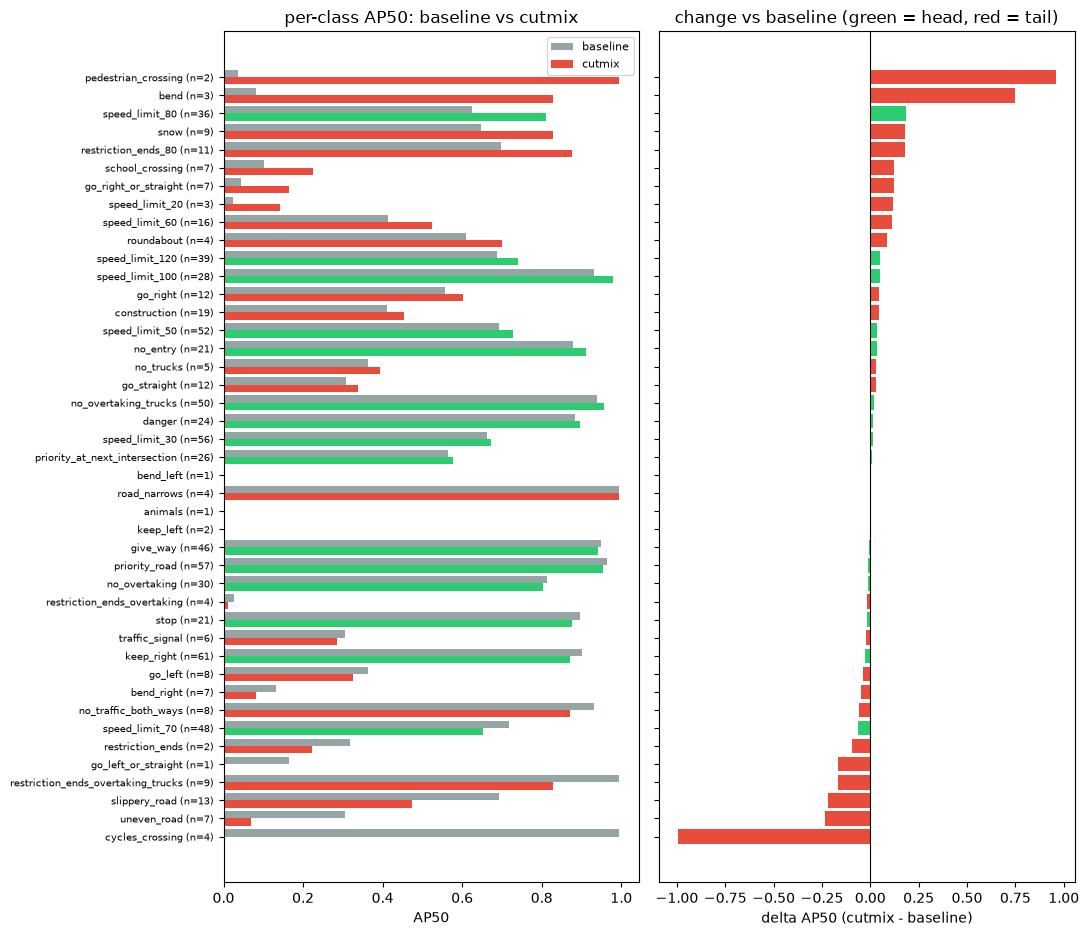

In [ ]:
if (RUNS / "cutmix" / "metrics.json").exists():
    display(group_delta_table("cutmix", RUNS).round(3))
    display(per_class_delta_table("cutmix", RUNS, CLASS_NAMES).round(3))
    per_class_delta_chart("cutmix", RUNS, CLASS_NAMES)
else:
    print("[cutmix: not evaluated yet - run gtsdb_eval first]")


#### Observations

Group deltas vs the baseline — mAP50 | Precision | Recall:

| group | mAP50 | Precision | Recall |
|---|---|---|---|
| overall | 0.549 (+0.023) | 0.577 (-0.093) | 0.530 (+0.058) |
| head | 0.824 (+0.018) | 0.706 (-0.011) | 0.852 (+0.070) |
| **tail** | 0.401 (+0.025) | 0.508 (-0.137) | 0.358 (+0.052) |

- **Tail classes:** 13 up / 15 down (of 28 present).
- **Top gains:** pedestrian_crossing +0.958, bend +0.746, speed_limit_80 +0.185.
- **Top drops:** cycles_crossing -0.995, uneven_road -0.236, slippery_road -0.220.



### cutmix: training curves



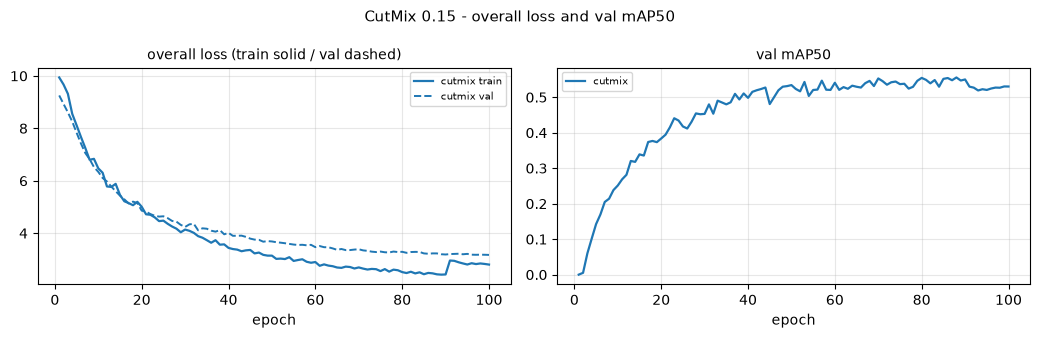

In [ ]:
if (RUNS / "cutmix" / "results.csv").exists():
    training_overview(["cutmix"], RUNS, "CutMix 0.15 - overall loss and val mAP50")
else:
    print("[cutmix: no results.csv yet - train this arm first]")


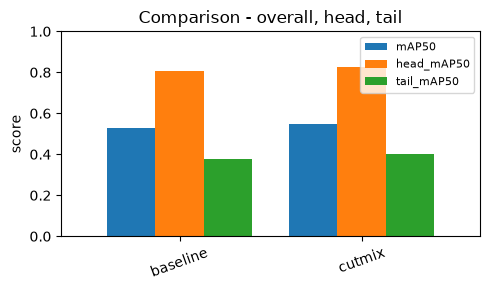

,mAP50,mAP50-95,Precision,Recall,head_mAP50,head_Precision,head_Recall,tail_mAP50,tail_Precision,tail_Recall
baseline,0.526,0.455,0.671,0.472,0.807,0.717,0.782,0.376,0.646,0.306
cutmix,0.549,0.478,0.577,0.530,0.824,0.706,0.852,0.401,0.508,0.358


In [ ]:
compare_arms_bars(["baseline", "cutmix"], RUNS)
display(metrics_table(["baseline", "cutmix"], RUNS).round(3))

## 8. Synthesis & Comparison



,mAP50,mAP50-95,Precision,Recall,head_mAP50,head_Precision,head_Recall,tail_mAP50,tail_Precision,tail_Recall
baseline,0.526,0.455,0.671,0.472,0.807,0.717,0.782,0.376,0.646,0.306
oversample,0.526,0.449,0.657,0.448,0.817,0.747,0.815,0.370,0.608,0.252
rfs,0.563,0.482,0.681,0.495,0.830,0.799,0.789,0.420,0.618,0.337
cls_pw,0.453,0.392,0.517,0.440,0.691,0.607,0.721,0.325,0.468,0.290
focal,0.530,0.459,0.651,0.457,0.831,0.763,0.782,0.368,0.590,0.283
cutmix,0.549,0.478,0.577,0.530,0.824,0.706,0.852,0.401,0.508,0.358


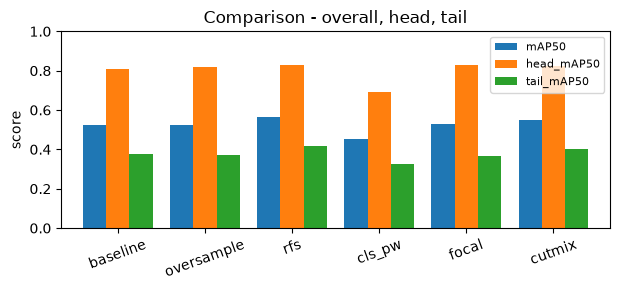

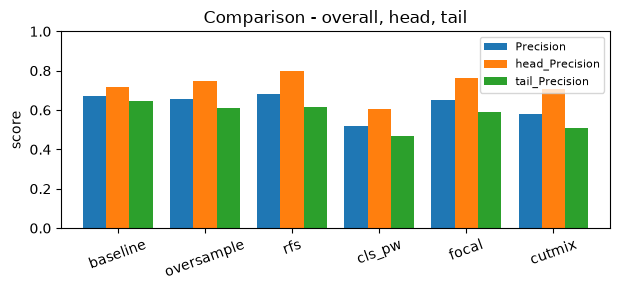

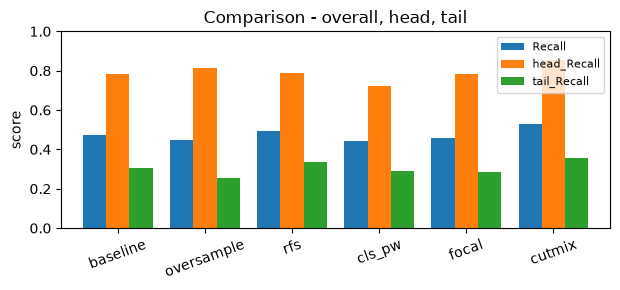

,Recall,head_Recall,tail_Recall
baseline,0.472367,0.782026,0.306478
oversample,0.448390,0.814719,0.252141
rfs,0.494717,0.788973,0.337080
cls_pw,0.440264,0.720712,0.290025
focal,0.457378,0.782175,0.283380
cutmix,0.530312,0.851989,0.357985


In [ ]:
ARMS = [a for a in [
    "baseline", "oversample", "rfs", "cls_pw", "focal", "cutmix",
] if (RUNS / a / "metrics.json").exists()]
table = metrics_table(ARMS, RUNS).round(3)
display(table)

compare_arms_bars(ARMS, RUNS, metric_keys=["mAP50", "head_mAP50", "tail_mAP50"])
compare_arms_bars(ARMS, RUNS, metric_keys=["Precision", "head_Precision", "tail_Precision"])
compare_arms_bars(ARMS, RUNS, metric_keys=["Recall", "head_Recall", "tail_Recall"])


### Cross-arm heatmaps & ranking

Group and per-class heatmaps across every evaluated arm, plus a tail-mAP50
ranking table.

,overall,head,tail
baseline,0.526,0.807,0.376
oversample,0.526,0.817,0.370
rfs,0.563,0.830,0.420
cls_pw,0.453,0.691,0.325
focal,0.530,0.831,0.368
cutmix,0.549,0.824,0.401


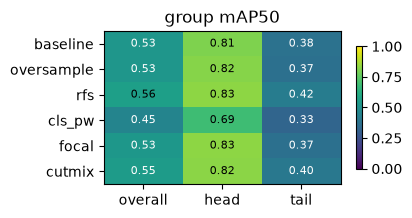

,speed_limit_20,speed_limit_30,speed_limit_50,speed_limit_60,speed_limit_70,speed_limit_80,restriction_ends_80,speed_limit_100,speed_limit_120,no_overtaking,...,go_right,go_left,go_straight,go_right_or_straight,go_left_or_straight,keep_right,keep_left,roundabout,restriction_ends_overtaking,restriction_ends_overtaking_trucks
baseline,0.024,0.662,0.692,0.414,0.718,0.625,0.697,0.930,0.689,0.814,...,0.557,0.362,0.307,0.045,0.166,0.900,0.000,0.610,0.027,0.995
oversample,0.016,0.668,0.607,0.531,0.716,0.830,0.995,0.973,0.756,0.668,...,0.589,0.166,0.331,0.055,0.000,0.926,0.014,0.948,0.006,0.495
rfs,0.017,0.558,0.678,0.552,0.640,0.873,0.898,0.973,0.767,0.788,...,0.459,0.349,0.384,0.276,0.000,0.879,0.000,0.551,0.067,0.995
cls_pw,0.100,0.655,0.531,0.355,0.251,0.457,0.955,0.973,0.433,0.575,...,0.495,0.195,0.255,0.181,0.083,0.884,0.000,0.710,0.034,0.828
focal,0.008,0.795,0.789,0.504,0.782,0.689,0.862,0.900,0.673,0.793,...,0.685,0.141,0.589,0.019,0.249,0.858,0.005,0.640,0.007,0.995
cutmix,0.142,0.673,0.727,0.524,0.652,0.810,0.875,0.980,0.739,0.803,...,0.602,0.325,0.338,0.165,0.000,0.871,0.000,0.699,0.010,0.828


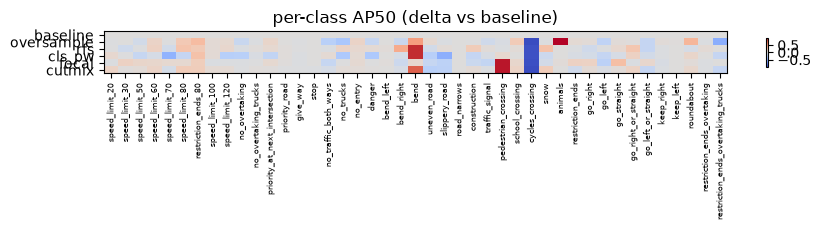

,rank,tail_AP50,arm
2,1,0.4196,rfs
5,2,0.4012,cutmix
0,3,0.3759,baseline
1,4,0.3701,oversample
4,5,0.3683,focal
3,6,0.3250,cls_pw


In [ ]:
display(metric_matrix(ARMS, RUNS, metric="mAP50").round(3))
group_heatmap(ARMS, RUNS, metric="mAP50")
display(per_class_heatmap(ARMS, RUNS, CLASS_NAMES, metric="AP50", plot=False).round(3))
per_class_heatmap(ARMS, RUNS, CLASS_NAMES, metric="AP50", baseline="baseline")
display(rank_arms(ARMS, RUNS, metric="tail_AP50").round(4))


### What the arms actually see

Below is a single validation image, cropped around one tail-class sign.

All 6/6 arms put a box on the sign
(IoU 0.92–0.95), but only 3/6 call it `construction`. 


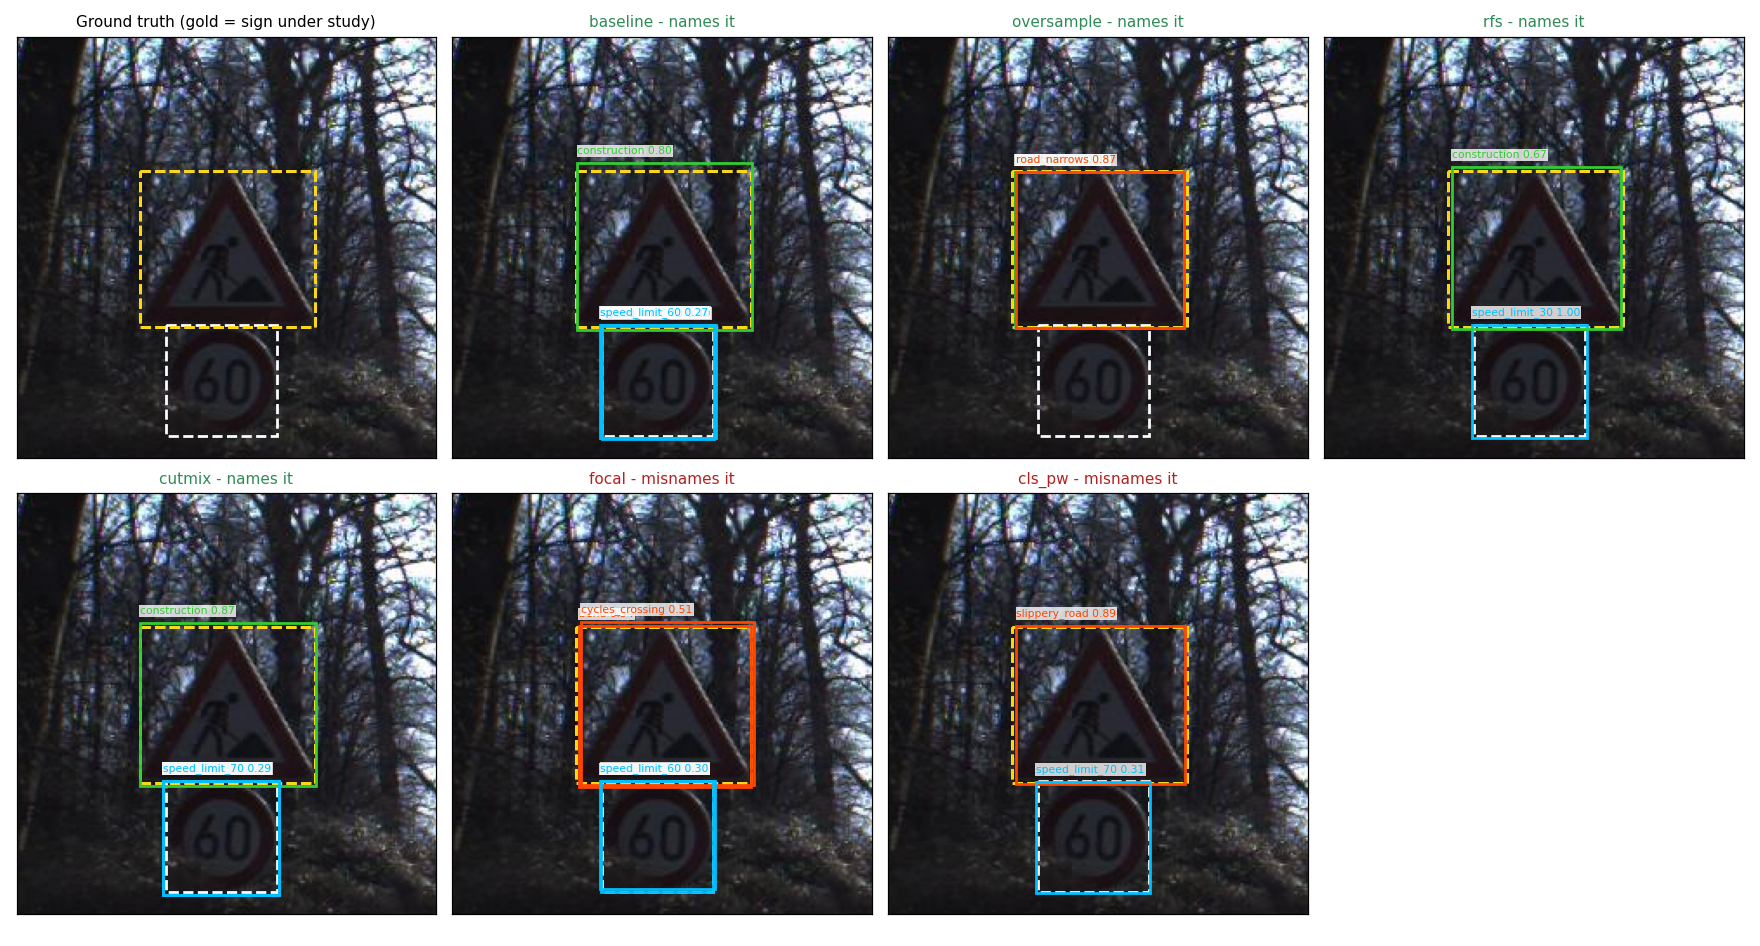

In [ ]:
from IPython.display import Image, display

display(Image("assets/detection_samples.png"))


## 9. Conclusion & Takeaways

- **The problem.** GTSDB is imbalanced. 
- **Data-level beats loss-level here.** The interventions that change *what the model
  sees* are the only ones that clearly help the tail:
  - **Repeat-factor sampling** lifts overall mAP50 to ~0.56 and the
    tail to ~0.42 (+0.044 over baseline)
  - **Oversampling does nothing** (tail -0.006): duplicating whole images shifts
    the prior without adding information.
  - **CutMix** improves tail (tail +0.025, overall 0.549), buying a large
    recall gain (0.47 -> 0.53) at a precision cost (0.67 -> 0.58).
- **Loss re-weighting did not fix the tail.** Focal loss mostly lifts the head:
  head mAP50 0.807 -> 0.831 while the tail stays flat (0.376 -> 0.368). Anti-correlating the loss with frequency (`cls_pw`) performed
  worst overall (-0.073 mAP50) as precision collapses to 0.52.

**Sumary for each run**
| intervention | verdict (tail mAP50) |
|---|---|
| `oversample` |  no effect, -0.006 — recall -0.054 |
| `rfs` |  **works, +0.044** — best performing, does not overfit |
| `cls_pw` |  **hurts, -0.051** — precision -0.154 |
| `focal` |  no effect, -0.008 — head-only gain (+0.025) |
| `cutmix` | works, **+0.025** — recall +0.058 at precision -0.093 |
